In [1]:
import pickle
import os

import numpy as np
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from models.model import *

torch.set_printoptions(sci_mode=False)

import lrp
from models.lrp_converter import convert

from PIL import Image

from utils import get_device, get_dataset, heatmap, project

/home/jack/anaconda3/envs/playing_cards/lib/python3.10/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
device = get_device()

Device: cuda:0 NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [5]:
class Transform():
	"""
	"""

	def __init__(self):
		self.transform = transforms.Compose([
			transforms.Resize((299, 299)),
			transforms.ToTensor(),
			transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[2, 2, 2])
		])

	def __call__(self, img, normalise=True):
		"""
		"""
		if normalise:
			return self.transform(img)
		else:
			return torch.as_tensor(transforms.Resize((299, 299))(img))

In [6]:
N_CONCEPT = 52
N_CLASSES = 6
NUM_IMG_OUTPUT = 1
USE_SIG = True
val_loader = load_data("./dataset/playing-cards/splits/three_card_class/val.pkl", 16, num_concepts=N_CONCEPT, dataset_root="./dataset/playing-cards/", return_orig=True, shuffle=True)

concept_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_poker_card_class/concepts.txt")
class_index_to_string = IndexToString("./dataset/playing-cards/splits/three_card_poker_card_class/classes.txt")

XtoCtoY = End2EndModel(num_classes=N_CLASSES, num_concepts=N_CONCEPT, num_images_per_output=NUM_IMG_OUTPUT, use_sigmoid=USE_SIG, use_modulelist=False)
XtoCtoY.load_state_dict(torch.load("./saves/XtoCtoY_converted.pth", map_location=torch.device('cpu')))
XtoCtoY.eval()

XtoC = convert(XtoCtoY.x_to_c_model)

XtoC_model_1 = []
XtoC_model_2 = []
XtoC_model_3 = []

for idx, m in enumerate(XtoC.children()):
	if idx < 15:
		XtoC_model_1.append(m)
	elif idx < 29:
		XtoC_model_2.append(m)
	else:
		XtoC_model_3.append(m)

XtoC_model_1 = lrp.Sequential(*XtoC_model_1).to(device)
XtoC_model_2 = lrp.Sequential(*XtoC_model_2).to(device)
XtoC_model_3 = lrp.Sequential(*XtoC_model_3).to(device)

print(XtoC_model_1)
print(XtoC_model_2)
print(XtoC_model_3)

Sequential(
  (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (9): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (10): ReLU()
  (11): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (12): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (13): ReLU()
  (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Sequential(
  (0): Conv2d(256, 5

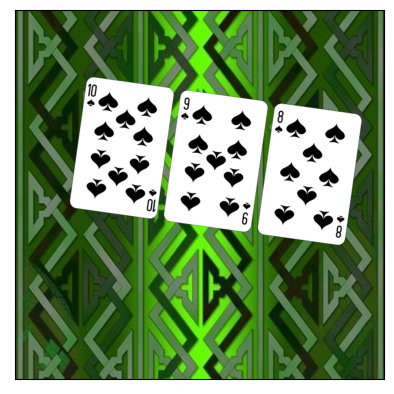

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


True image size (channels, width, height): torch.Size([1, 3, 299, 299])


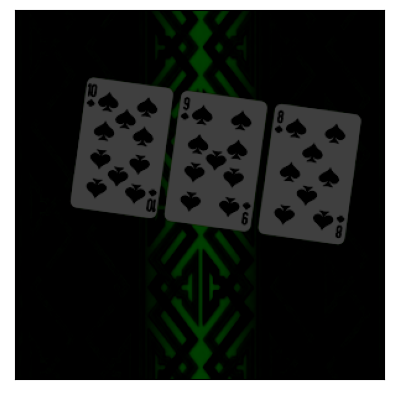

In [18]:
image = Image.open(os.path.join("dataset", "playing-cards", "imgs", "three_card_poker", "0.png")).convert('RGB')

image = Image.open(os.path.join("/home/jack/Documents/programming/playing-cards-demo/playing_cards_app/uploads/5.png")).convert('RGB')

plt.xticks([])
plt.yticks([])
plt.imshow(image)
plt.show()

image = Transform()(image)
image = image.unsqueeze(0)
image.requires_grad_(True)
image.grad = None  # Reset gradient

image = image.to(device)

# print / show input
print("True image size (channels, width, height):", image.size())

plt.xticks([])
plt.yticks([])
plt.imshow(image.cpu().squeeze().permute(1, 2, 0).detach().numpy())
plt.show()

In [22]:
# get model prediction and LRP map for classification
output_1 = XtoC_model_1.forward(image, explain=True, rule="alpha1beta0")
output_2 = XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
pred_concepts = XtoC_model_3.forward(output_2, explain=True, rule="gradient")

print(pred_concepts)

pred_concepts_readable = torch.nn.Sigmoid()(pred_concepts)
print("Predicted concepts:", pred_concepts_readable)

# print concept as string if prediction is >= 0.5
for idx, i in enumerate(pred_concepts_readable[0]):
    if i.item() >= 0.5:
        print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")
    #print(f"id: {idx},", f"concept name: {concept_index_to_string(idx)},", f"sig value: {i.item()}")

tensor([[-13.0909, -12.0564, -10.4731,   0.7790, -20.9276, -17.8787, -19.8659,
         -11.2584, -21.4823, -19.4312, -26.4935, -15.8494, -15.7006, -16.5411,
         -17.5625, -11.1170, -19.7889, -21.7586, -26.5811, -21.1480, -17.4483,
         -22.6241, -19.9600, -20.1961, -15.3154, -15.2364, -20.4801,  -4.6609,
         -12.2872, -10.4814, -14.1289,   1.2334, -12.7142, -12.8681, -13.6629,
           0.9617, -21.0608, -20.3797, -20.0543, -13.6090, -13.4439, -14.3553,
         -17.8386, -10.9717, -15.0729, -17.9876, -20.2212, -13.9611, -18.4618,
         -15.9831, -20.7321, -14.8737]], device='cuda:0',
       grad_fn=<AddmmBackward0>)
Predicted concepts: tensor([[    0.0000,     0.0000,     0.0000,     0.6855,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
            

In [20]:
class Model():
	def __init__(
		self,
		n_img_out=1,
		use_sig=True,
		n_concepts=52,
		n_classes=6,
		concept_index_to_string="./dataset/playing-cards/splits/three_card_poker_card_class/concepts.txt",
		concept_index_to_full_name="./dataset/playing-cards/splits/three_card_poker_card_class/concepts.txt",
		class_index_to_string="./dataset/playing-cards/splits/three_card_poker_card_class/classes.txt",
		class_index_to_description="./dataset/playing-cards/splits/three_card_poker_card_class/classes.txt",
		img_transform=Transform(),
		XtoCtoY_path="./saves/XtoCtoY_converted.pth"
		):
		super(Model, self).__init__()

		self.use_sig = use_sig
		self.concept_index_to_string = IndexToString(concept_index_to_string)
		self.class_index_to_string = IndexToString(class_index_to_string)
		self.class_index_to_description = IndexToString(class_index_to_description)
		self.concept_index_to_full_name = IndexToString(concept_index_to_full_name)
		self.img_transform = img_transform

		self.device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
		self.device = "cpu"
		if torch.cuda.is_available():
			print("Device:", self.device, torch.cuda.get_device_name(0))
		else:
			print("Device:", self.device)


		XtoCtoY = End2EndModel(num_classes=n_classes, num_concepts=n_concepts, num_images_per_output=n_img_out, use_sigmoid=self.use_sig, use_modulelist=False)
		XtoCtoY.load_state_dict(torch.load(XtoCtoY_path, map_location=torch.device('cpu')))
		XtoCtoY.eval()
		XtoC = convert(XtoCtoY.x_to_c_model)

		XtoC_model_1 = []
		XtoC_model_2 = []
		XtoC_model_3 = []

		for idx, m in enumerate(XtoC.children()):
			if idx < 15:
				XtoC_model_1.append(m)
			elif idx < 29:
				XtoC_model_2.append(m)
			else:
				XtoC_model_3.append(m)

		self.XtoC_model_1 = lrp.Sequential(*XtoC_model_1)
		self.XtoC_model_2 = lrp.Sequential(*XtoC_model_2)
		self.XtoC_model_3 = lrp.Sequential(*XtoC_model_3)

		self.XtoC_model_1.to(self.device)
		self.XtoC_model_2.to(self.device)
		self.XtoC_model_3.to(self.device)
		
		
		
		
		
		
		self.CtoY = XtoCtoY.c_to_y_model.to(self.device)

		self.raw_input = None  # unultered input image
		self.transformed_input = None  # input image with a transformation
		self.input_name = None  # file name of input image
		self.input_path = None  # path to input image
		self.pred_concepts = None  # X to C model part output
		self.task_out = None  # C to Y model part output
		self.concepts = None  # concept out (after sigmoid or intevention)

		self.thread = threading.Semaphore()
		
		
		self.temp = XtoCtoY.x_to_c_model

	def predict(self, concepts=None):
		""" pass an input image through a model to get a prediction for task and concepts.
		Optionaly also generate and save concept saliency maps

		args:
			concepts (None / list of floats): List of concepts (only used for C to Y / interveneing)
		"""

		# C to Y only
		if concepts != None:
			c_to_y_input = torch.FloatTensor(concepts).unsqueeze(0).to(self.device)
		# End to end
		else:
			# Transform image and prepare for input to model
			self.transformed_input = self.img_transform(self.raw_input).to(self.device)
			self.transformed_input = self.transformed_input.unsqueeze(0)
			self.transformed_input.requires_grad_(True)
			self.transformed_input.grad = None  # Reset gradient
			
			#prediction = self.temp(self.transformed_input)
			
			#print(prediction)

			# Predict concepts
			output_1 = self.XtoC_model_1.forward(self.transformed_input, explain=True, rule="alpha1beta0")
			output_2 = self.XtoC_model_2.forward(output_1, explain=True, rule="epsilon")
			self.pred_concepts = self.XtoC_model_3.forward(output_2, explain=True, rule="gradient")
			
			print(self.pred_concepts)

			# Prepare concept predictions for task prediction
			outputs = []
			for out in [self.pred_concepts]:
				outputs.append(out)
			if self.use_sig:
				c_to_y_input = torch.nn.Sigmoid()(torch.cat(outputs, dim=1))
				sig_concepts = c_to_y_input
			else:
				c_to_y_input = torch.cat((outputs), dim=1)
				sig_concepts = torch.nn.Sigmoid()(torch.cat(outputs, dim=1))

			concepts = sig_concepts[0].tolist()

		self.concepts = concepts

		self.task_out = self.CtoY(c_to_y_input)

		print(c_to_y_input)

	def get_results(self, sort="index"):
		""" Return model outputs and string conversion

		args:
			sort (string): how the concepts should be sorted
				options:
					index: sorted by concept index (0 first)
					softmax: sorted by softmax value (highest first)
					concept: sorted by concept value (highest first)

		returns:
			task prediction string: string name for task prediction
			task prediction description: description of task prediction
			concept_out (list of tuples): list of concept predictions in the form
				(concept ID, concept string, concept value, concept name, concept softmax score)
		"""

		_, predicted = self.task_out.max(1)

		softmax_score = F.softmax(self.pred_concepts, dim=-1)

		concept_out = []
		for idx, i in enumerate(self.concepts):
			concept_out.append((idx, self.concept_index_to_string(idx), i, self.concept_index_to_full_name(idx), softmax_score[0][idx].item()))

		indexed_concepts = [(x[0], x[1], x[2]) for x in concept_out]  # concept index, string and value in order of index

		if sort == "index":
			pass  # no need to sort
		elif sort == "softmax":
			sorted_concept_out = sorted(concept_out, key=lambda tup: tup[4], reverse=True)
		elif sort == "concept":
			sorted_concept_out = sorted(concept_out, key=lambda tup: tup[2], reverse=True)

		return self.class_index_to_string(predicted.item()), self.class_index_to_description(predicted.item()), sorted_concept_out, indexed_concepts

	def gen_saliency(self, concept_id, cmap="seismic", **kwargs):
		"""
		Generate and save saleincy map for a given concept

		args:
			concept_id (int): ID of the concept to generate a saleincy map of
			cmap (string): Name of matplotlib colour map to use
			**kwargs: additional variables which are passed directly to save_image()
		"""
		self.thread.acquire()  # add lock to avoid CUDA out of memory error
		filename = f"{concept_id}_{self.input_name}"
		# Only generate saliency map if it does not already exist
		if os.path.exists(f"{os.path.dirname(self.input_path)}/{filename}") == False:
			attr = get_saliency(self.pred_concepts, self.transformed_input, concept_id, cmap_name=cmap)
			save_image(filename=filename, img=attr.squeeze(), type="plt", **kwargs)
		self.thread.release()

		return filename

	def set_input(self, path):
		"""
		replaces the model input with a new image. Any alpha channel is removed

		args:
			image (string): file path to input image
		"""
		# remove old input + results from model and memory
		del self.raw_input
		del self.transformed_input
		del self.pred_concepts
		del self.task_out

		# add new input to class instance
		self.input_path = path
		self.input_name = os.path.basename(path)
		self.raw_input = Image.open(self.input_path).convert('RGB')
		#self.raw_input = Image.open(self.input_path).convert('RGBA')
		#background = Image.new('RGBA', self.raw_input.size, (255,255,255))
		#self.raw_input = Image.alpha_composite(background, self.raw_input)
		#self.raw_input = self.raw_input.convert('RGB')

In [26]:
CURRENT_MODEL = Model()

Device: cpu NVIDIA GeForce RTX 3050 Ti Laptop GPU


In [27]:
CURRENT_MODEL.set_input(os.path.join("dataset", "playing-cards", "imgs", "three_card_poker", "0.png"))
CURRENT_MODEL.predict()

task_out, task_desc, concept_out, indexed_concepts = CURRENT_MODEL.get_results(sort="concept")

print(task_out)

print(concept_out)

tensor([[-10.6949,  -9.7352,  -6.5268,  -8.3461, -17.6097, -16.6565, -10.6879,
         -13.6488, -20.2228, -18.7975, -11.1439, -21.3223, -18.1340, -18.0006,
         -11.6496, -16.7646, -19.1450, -16.8215, -11.6856, -20.7104, -16.6446,
         -13.3888,  -7.5964, -14.4473, -16.1313, -10.7908,   1.1959,  -9.6396,
         -15.1510, -14.6860,   1.0955, -11.3029, -14.8846,  -9.4898,   1.2458,
         -10.8892, -14.6418, -15.5531,  -8.9474, -13.4538, -13.7883, -15.2453,
         -11.5881, -13.4886, -16.9240, -20.5654, -16.5167, -16.7670, -21.4242,
         -18.6347, -14.3382, -17.1205]], grad_fn=<AddmmBackward0>)
tensor([[    0.0000,     0.0001,     0.0015,     0.0002,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0000,     0.0000,
             0.0000,     0.0000,     0.0000,     0.0000,     0.0005,     0.0000,
             0.0000,     0.0000,     0.7678,     0.0001,

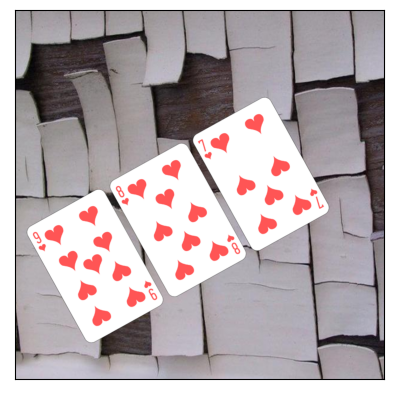

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


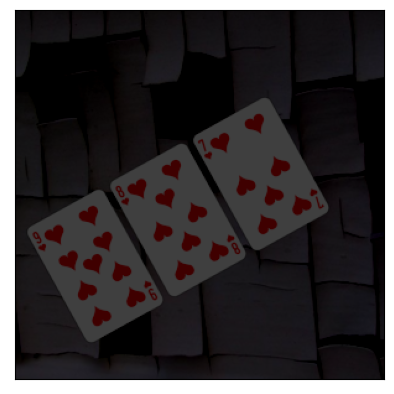

In [17]:
plt.xticks([])
plt.yticks([])
plt.imshow(CURRENT_MODEL.raw_input)
plt.show()

plt.xticks([])
plt.yticks([])
plt.imshow(CURRENT_MODEL.transformed_input.cpu().squeeze().permute(1, 2, 0).detach().numpy())
plt.show()